# 04 · Evaluation on held-out geographic blocks
**Machine Learning and Data Analytics, Coursework 1 · Student ID: 18503**

Notebook 03 chose and fitted the models using block-grouped cross-validation on the training blocks only. This notebook scores them **once** on the 20% of geographic blocks that were never used for training or tuning, and then looks at where and why they fail.

Sections: (1) setup and the held-out set, (2) Task A occurrence, (3) Task B hours, (4) the two parts combined, (5) Task C gear type, (6) what drives the predictions, (7) does a random split overstate performance, (8) a bias audit across regions and flag groups, (9) summary.

Confidence intervals are 95% **block bootstrap** intervals: whole test blocks are resampled, because rows in the same block are not independent.

In [1]:
import os, sys, json, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src import features as F
from src import plotstyle as P
P.apply()

import joblib
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, cross_val_predict, train_test_split
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve, precision_recall_curve, f1_score,
                             precision_score, recall_score, balanced_accuracy_score, confusion_matrix,
                             mean_squared_error, mean_absolute_error, r2_score, accuracy_score, classification_report)
from scipy.stats import spearmanr

DATA = ROOT / "data" / "processed" / "fishing_sample.parquet"
FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
MODELS = ROOT / "models"
SEED = F.SEED
FAST = os.environ.get("CW_FAST") == "1"
N_BOOT = 30 if FAST else 200
RES = {}

df = F.prepare(F.load_sample(DATA))
train_idx, test_idx = F.geo_split(df)
train = df.iloc[train_idx].reset_index(drop=True)
test = df.iloc[test_idx].reset_index(drop=True)
assert not (set(train["block"]) & set(test["block"])), "train and test share a block"
print(f"Train {len(train):,} rows / {train['block'].nunique()} blocks | Test {len(test):,} rows / {test['block'].nunique()} blocks")
print(f"Share with fishing: train {train['any_fishing'].mean():.3f} | test {test['any_fishing'].mean():.3f}")

def load(name):
    d = joblib.load(MODELS / f"{name}.joblib"); return d["pipeline"], d["columns"]

def boot_ci(frame, fn, n=N_BOOT, seed=SEED):
    # fn(positional_index_array) -> float; resamples whole blocks of `frame`
    rng = np.random.default_rng(seed)
    b = frame["block"].to_numpy()
    groups = [np.flatnonzero(b == k) for k in np.unique(b)]
    vals = []
    for _ in range(n):
        pick = rng.integers(0, len(groups), len(groups))
        try: vals.append(fn(np.concatenate([groups[i] for i in pick])))
        except ValueError: pass
    return tuple(np.percentile(vals, [2.5, 97.5]))

def ci_str(v, ci): return f"{v:.3f} [{ci[0]:.3f}, {ci[1]:.3f}]"
def clean(o):
    if isinstance(o, dict): return {str(k): clean(v) for k, v in o.items()}
    if isinstance(o, (np.floating, np.integer)): return float(o)
    if isinstance(o, (tuple, list)): return [clean(x) for x in o]
    return o

Train 237,895 rows / 376 blocks | Test 81,267 rows / 95 blocks
Share with fishing: train 0.309 | test 0.343


## 1. Task A · Will any fishing occur?
Set A is the deployable model (location, season, gear, flag, vessel summaries). Set B also sees total activity (`hours`, `mmsi_present`) and is an upper bound, not a usable model.

Notebook 03 showed that tree models score poorly on F1 at the default 0.5 cut-off because only about 32% of rows are positive, while the class-weighted logistic regression does not. The cut-off is a **decision threshold**, not part of the model, so it is chosen here from out-of-fold predictions on the **training** blocks and then applied unchanged to the test blocks.

In [2]:
pipeA, colsA = load("occurrence_A"); pipeB, colsB = load("occurrence_B")
y = test["any_fishing"].to_numpy()
pA = pipeA.predict_proba(test[colsA])[:, 1]
pB = pipeB.predict_proba(test[colsB])[:, 1]

# Threshold from training out-of-fold predictions (never from the test set)
n_thr = 30000 if FAST else 100000
sub = train.sample(min(len(train), n_thr), random_state=SEED)
def best_threshold(pipe, cols):
    oof = cross_val_predict(clone(pipe), sub[cols], sub["any_fishing"], groups=sub["block"],
                            cv=GroupKFold(n_splits=3 if FAST else 5), method="predict_proba")[:, 1]
    pr, rc, th = precision_recall_curve(sub["any_fishing"], oof)
    f1 = 2 * pr * rc / (pr + rc + 1e-12)
    return float(th[np.argmax(f1[:-1])])
thrA, thrB = best_threshold(pipeA, colsA), best_threshold(pipeB, colsB)
print(f"Chosen thresholds from training folds: set A {thrA:.3f} | set B {thrB:.3f}")

Chosen thresholds from training folds: set A 0.295 | set B 0.401


In [3]:
rows = {}
for label, p, thr in [("Set A (deployable)", pA, thrA), ("Set B (+ hours, mmsi_present)", pB, thrB)]:
    roc = roc_auc_score(y, p); pr = average_precision_score(y, p)
    r = {"ROC-AUC": ci_str(roc, boot_ci(test, lambda i, p=p: roc_auc_score(y[i], p[i]))),
         "PR-AUC": ci_str(pr, boot_ci(test, lambda i, p=p: average_precision_score(y[i], p[i])))}
    for tag, t in [("@0.5", 0.5), ("@tuned", thr)]:
        yh = (p >= t).astype(int)
        r[f"F1 {tag}"] = round(f1_score(y, yh), 3); r[f"precision {tag}"] = round(precision_score(y, yh), 3)
        r[f"recall {tag}"] = round(recall_score(y, yh), 3); r[f"bal.acc {tag}"] = round(balanced_accuracy_score(y, yh), 3)
    rows[label] = r
    RES.setdefault("A", {})[label] = {"roc_auc": roc, "pr_auc": pr, "threshold": thr,
                                       "f1_default": r["F1 @0.5"], "f1_tuned": r["F1 @tuned"]}
tabA = pd.DataFrame(rows).T
print(f"Test prevalence (PR-AUC of a random guesser): {y.mean():.3f}")
tabA.T

Test prevalence (PR-AUC of a random guesser): 0.343


,Set A (deployable),"Set B (+ hours, mmsi_present)"
ROC-AUC,"0.720 [0.674, 0.762]","0.896 [0.881, 0.916]"
PR-AUC,"0.562 [0.463, 0.646]","0.823 [0.793, 0.858]"
F1 @0.5,0.396,0.747
precision @0.5,0.635,0.76
recall @0.5,0.288,0.735
bal.acc @0.5,0.601,0.807
F1 @tuned,0.577,0.757
precision @tuned,0.454,0.72
recall @tuned,0.789,0.797
bal.acc @tuned,0.647,0.818


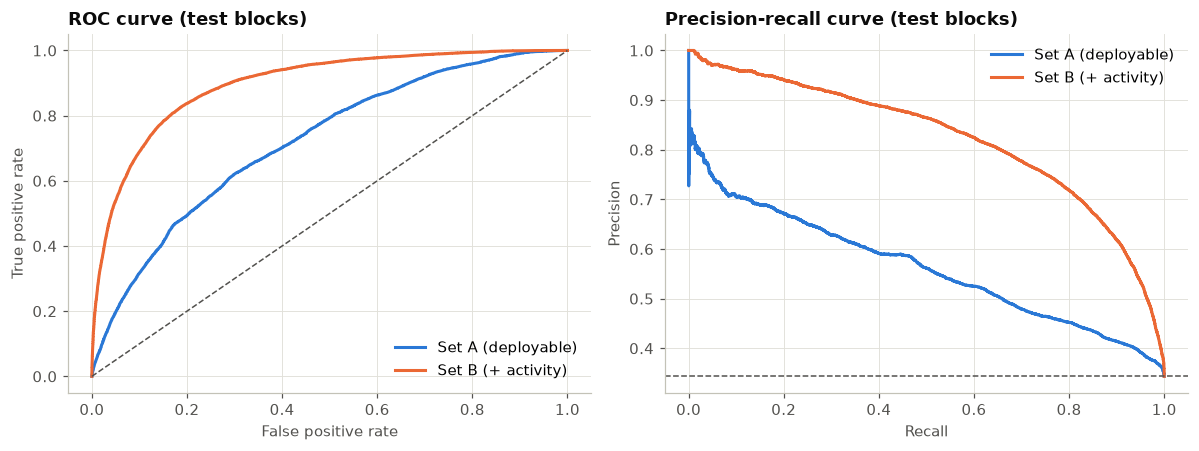

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
for p, lab, col in [(pA, "Set A (deployable)", P.BLUE), (pB, "Set B (+ activity)", P.ORANGE)]:
    fpr, tpr, _ = roc_curve(y, p); ax[0].plot(fpr, tpr, color=col, lw=2, label=lab)
    pr, rc, _ = precision_recall_curve(y, p); ax[1].plot(rc, pr, color=col, lw=2, label=lab)
ax[0].plot([0, 1], [0, 1], color=P.MUTED, lw=1, ls="--"); ax[0].set_title("ROC curve (test blocks)")
ax[0].set_xlabel("False positive rate"); ax[0].set_ylabel("True positive rate"); ax[0].legend(frameon=False)
ax[1].axhline(y.mean(), color=P.MUTED, lw=1, ls="--"); ax[1].set_title("Precision-recall curve (test blocks)")
ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision"); ax[1].legend(frameon=False)
fig.tight_layout(); P.save(fig, FIG / "17_taskA_curves.png")

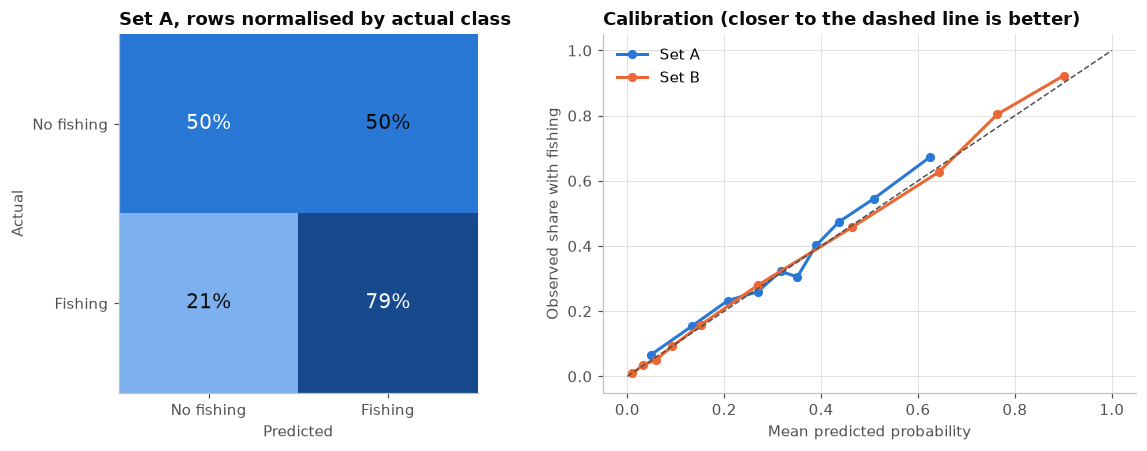

In [5]:
# Confusion matrix and calibration for the deployable model (set A) at the tuned threshold
yh = (pA >= thrA).astype(int)
cm = confusion_matrix(y, yh, normalize="true")
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
im = ax[0].imshow(cm, cmap=P.SEQ, vmin=0, vmax=1)
for i in range(2):
    for j in range(2):
        ax[0].text(j, i, f"{cm[i, j]:.0%}", ha="center", va="center", color="white" if cm[i, j] > 0.5 else P.INK, fontsize=13)
ax[0].set_xticks([0, 1]); ax[0].set_xticklabels(["No fishing", "Fishing"]); ax[0].set_yticks([0, 1]); ax[0].set_yticklabels(["No fishing", "Fishing"])
ax[0].set_xlabel("Predicted"); ax[0].set_ylabel("Actual"); ax[0].grid(False); ax[0].set_title("Set A, rows normalised by actual class")
for p, lab, col in [(pA, "Set A", P.BLUE), (pB, "Set B", P.ORANGE)]:
    frac, mean_p = calibration_curve(y, p, n_bins=10, strategy="quantile")
    ax[1].plot(mean_p, frac, color=col, lw=2, marker="o", ms=5, label=lab)
ax[1].plot([0, 1], [0, 1], color=P.MUTED, lw=1, ls="--"); ax[1].set_title("Calibration (closer to the dashed line is better)")
ax[1].set_xlabel("Mean predicted probability"); ax[1].set_ylabel("Observed share with fishing"); ax[1].legend(frameon=False)
fig.tight_layout(); P.save(fig, FIG / "18_taskA_confusion_calibration.png")

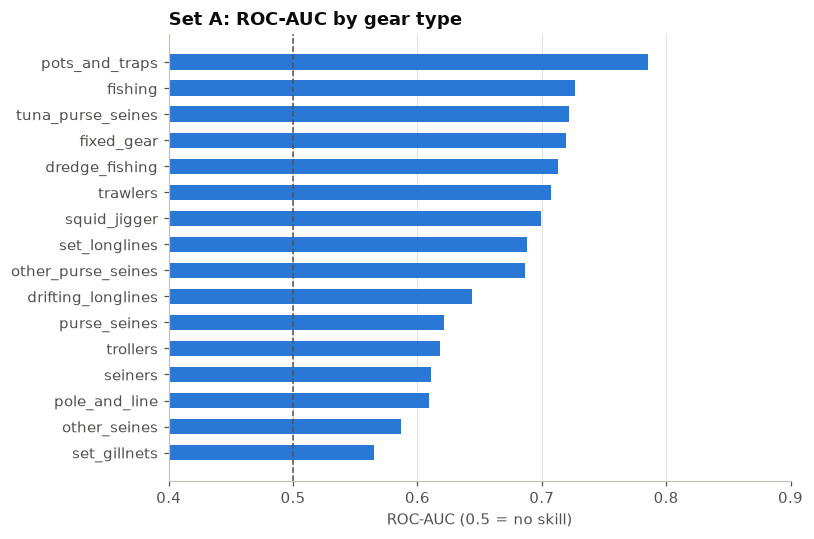

,rows,share_fishing,roc_auc
geartype,,,
set_gillnets,5366,0.572,0.565
other_seines,11142,0.377,0.587
pole_and_line,4129,0.238,0.609
seiners,6127,0.240,0.611
trollers,5352,0.252,0.618
purse_seines,4661,0.246,0.622
drifting_longlines,3855,0.517,0.644
other_purse_seines,5507,0.294,0.687
set_longlines,4967,0.408,0.688


In [6]:
# Where does set A work and fail? ROC-AUC by gear type on the test blocks
g = []
for gear, idx in test.groupby("geartype").indices.items():
    if len(np.unique(y[idx])) == 2:
        g.append({"geartype": gear, "rows": len(idx), "share_fishing": y[idx].mean(), "roc_auc": roc_auc_score(y[idx], pA[idx])})
byA = pd.DataFrame(g).set_index("geartype").sort_values("roc_auc")
RES["A_by_gear"] = byA["roc_auc"].round(3).to_dict()
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.barh(byA.index, byA["roc_auc"], color=P.BLUE, height=0.6); ax.axvline(0.5, color=P.MUTED, lw=1, ls="--")
ax.set_xlim(0.4, max(0.9, byA["roc_auc"].max() + 0.02)); ax.set_xlabel("ROC-AUC (0.5 = no skill)"); ax.set_title("Set A: ROC-AUC by gear type")
ax.grid(axis="y", visible=False); fig.tight_layout(); P.save(fig, FIG / "19_taskA_by_gear.png")
byA.round(3)

## 2. Task B · How many hours, where fishing occurs?
Evaluated on test rows with fishing only. Errors are on the `log1p(hours)` scale. The baseline predicts the training mean.

In [7]:
test_pos = test[test["any_fishing"] == 1].reset_index(drop=True)
train_pos = train[train["any_fishing"] == 1]
hA, hcolsA = load("hours_A"); hB, hcolsB = load("hours_B")
yt = test_pos["log_fishing_hours"].to_numpy()
qA = hA.predict(test_pos[hcolsA]); qB = hB.predict(test_pos[hcolsB])
base = np.full_like(yt, train_pos["log_fishing_hours"].mean())

def reg_row(pred):
    return {"RMSE": ci_str(np.sqrt(mean_squared_error(yt, pred)),
                           boot_ci(test_pos, lambda i: np.sqrt(mean_squared_error(yt[i], pred[i])))),
            "MAE": round(mean_absolute_error(yt, pred), 3), "R2": round(r2_score(yt, pred), 3)}
tabB = pd.DataFrame({"Baseline (train mean)": reg_row(base), "Set A (deployable)": reg_row(qA),
                     "Set B (+ hours, mmsi_present)": reg_row(qB)}).T
RES["B"] = {k: {"rmse": float(np.sqrt(mean_squared_error(yt, p))), "mae": float(mean_absolute_error(yt, p)), "r2": float(r2_score(yt, p))}
            for k, p in [("baseline", base), ("A", qA), ("B", qB)]}
tabB

,RMSE,MAE,R2
Baseline (train mean),"1.330 [1.134, 1.467]",1.086,-0.002
Set A (deployable),"1.215 [1.014, 1.325]",0.975,0.165
"Set B (+ hours, mmsi_present)","0.646 [0.502, 0.734]",0.429,0.763


In [8]:
# How much of set B's gain is nearly automatic? fishing_hours can never exceed hours.
all_fishing = (test_pos["fishing_hours"] >= 0.999 * test_pos["hours"]).mean()
print(f"Rows where ALL recorded hours were fishing hours: {all_fishing:.1%}")
print("In those rows set B only has to copy `hours`, so its R2 overstates real predictive skill.")
RES["B_share_all_fishing"] = float(all_fishing)

Rows where ALL recorded hours were fishing hours: 20.2%
In those rows set B only has to copy `hours`, so its R2 overstates real predictive skill.


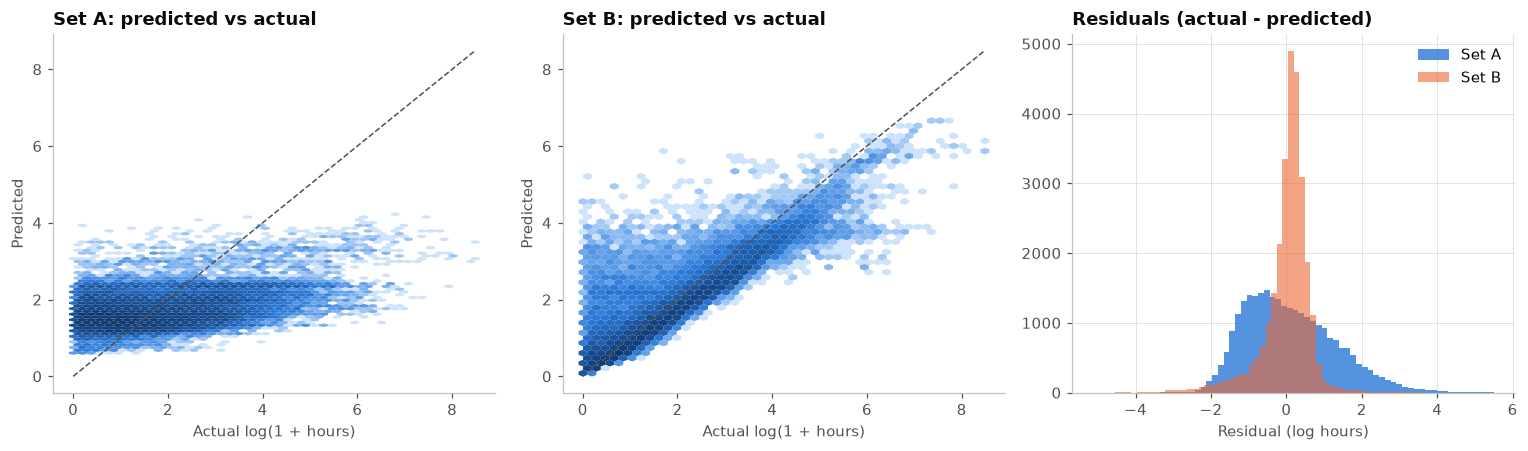

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4.2))
lim = [0, max(yt.max(), qA.max(), qB.max())]
for a, p, t in [(ax[0], qA, "Set A: predicted vs actual"), (ax[1], qB, "Set B: predicted vs actual")]:
    hb = a.hexbin(yt, p, gridsize=45, cmap=P.SEQ, mincnt=1, bins="log", linewidths=0)
    a.plot(lim, lim, color=P.MUTED, lw=1, ls="--"); a.set_xlabel("Actual log(1 + hours)"); a.set_ylabel("Predicted"); a.set_title(t); a.grid(False)
ax[2].hist(yt - qA, bins=60, color=P.BLUE, alpha=0.8, label="Set A")
ax[2].hist(yt - qB, bins=60, color=P.ORANGE, alpha=0.6, label="Set B")
ax[2].set_title("Residuals (actual - predicted)"); ax[2].set_xlabel("Residual (log hours)"); ax[2].legend(frameon=False)
fig.tight_layout(); P.save(fig, FIG / "20_taskB_fit.png")

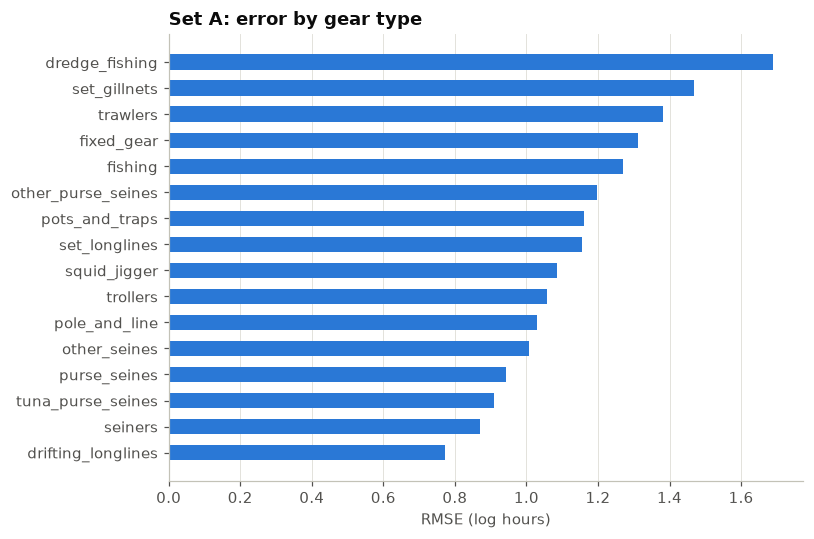

,rows,rmse
geartype,,
drifting_longlines,1994,0.773
seiners,1472,0.869
tuna_purse_seines,391,0.910
purse_seines,1145,0.943
other_seines,4202,1.008
pole_and_line,982,1.029
trollers,1347,1.057
squid_jigger,75,1.086
set_longlines,2028,1.157


In [10]:
rm = (test_pos.assign(err2=(yt - qA) ** 2).groupby("geartype").agg(rows=("err2", "size"), rmse=("err2", lambda s: np.sqrt(s.mean())))
      .sort_values("rmse"))
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.barh(rm.index, rm["rmse"], color=P.BLUE, height=0.6); ax.set_xlabel("RMSE (log hours)"); ax.set_title("Set A: error by gear type")
ax.grid(axis="y", visible=False); fig.tight_layout(); P.save(fig, FIG / "21_taskB_by_gear.png")
rm.round(3)

## 3. The two parts combined
Expected effort = P(any fishing) × predicted hours. Because `expm1` of an average log is closer to a typical value than to the mean, this is used only as a **ranking** score: does it order all test cells from least to most fishing? Spearman correlation with the actual `fishing_hours` (including the zeros).

In [11]:
qA_all = hA.predict(test[hcolsA]); qB_all = hB.predict(test[hcolsB])
expA = pA * np.expm1(qA_all); expB = pB * np.expm1(qB_all)
rhoA = spearmanr(expA, test["fishing_hours"]).statistic; rhoB = spearmanr(expB, test["fishing_hours"]).statistic
RES["two_part_spearman"] = {"A": float(rhoA), "B": float(rhoB)}
pd.Series({"Set A (deployable)": rhoA, "Set B (+ activity)": rhoB}, name="Spearman, expected vs actual fishing hours").round(3).to_frame()

,"Spearman, expected vs actual fishing hours"
Set A (deployable),0.365
Set B (+ activity),0.692


## 4. Task C · Which gear type is it?
The model sees location, season, flag and activity, but no vessel summaries. Several GFW gear classes overlap in meaning (for example `purse_seines`, `other_purse_seines` and `tuna_purse_seines`), so mistakes between related classes are expected. We therefore also score at the level of gear **families**.

In [12]:
gm, gcols = load("gear")
yg = test["geartype"].to_numpy(); pg = gm.predict(test[gcols])
mf1 = f1_score(yg, pg, average="macro"); acc = accuracy_score(yg, pg)
ci = boot_ci(test, lambda i: f1_score(yg[i], pg[i], average="macro"))
print(f"Macro-F1 {ci_str(mf1, ci)} | accuracy {acc:.3f} | chance level for 16 balanced classes 0.0625")
rep = pd.DataFrame(classification_report(yg, pg, output_dict=True, zero_division=0)).T.drop(["accuracy", "macro avg", "weighted avg"])
rep = rep.sort_values("f1-score")
RES["C"] = {"macro_f1": float(mf1), "macro_f1_ci": list(ci), "accuracy": float(acc)}
rep.round(3)

Macro-F1 0.391 [0.333, 0.480] | accuracy 0.370 | chance level for 16 balanced classes 0.0625


,precision,recall,f1-score,support
fixed_gear,0.154,0.102,0.123,4580.0
fishing,0.200,0.092,0.126,4169.0
set_gillnets,0.233,0.143,0.178,5366.0
dredge_fishing,0.155,0.523,0.239,5304.0
purse_seines,0.487,0.199,0.282,4661.0
set_longlines,0.343,0.254,0.292,4967.0
other_seines,0.750,0.185,0.297,11142.0
trawlers,0.253,0.495,0.335,5872.0
seiners,0.516,0.348,0.416,6127.0
pots_and_traps,0.372,0.516,0.432,4012.0


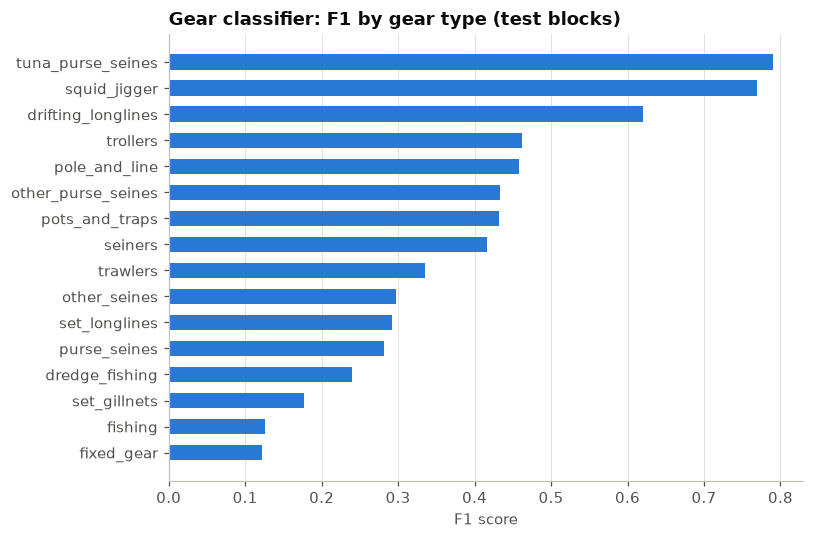

In [13]:
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.barh(rep.index, rep["f1-score"], color=P.BLUE, height=0.6); ax.set_xlabel("F1 score"); ax.set_title("Gear classifier: F1 by gear type (test blocks)")
ax.grid(axis="y", visible=False); fig.tight_layout(); P.save(fig, FIG / "22_taskC_f1_by_gear.png")

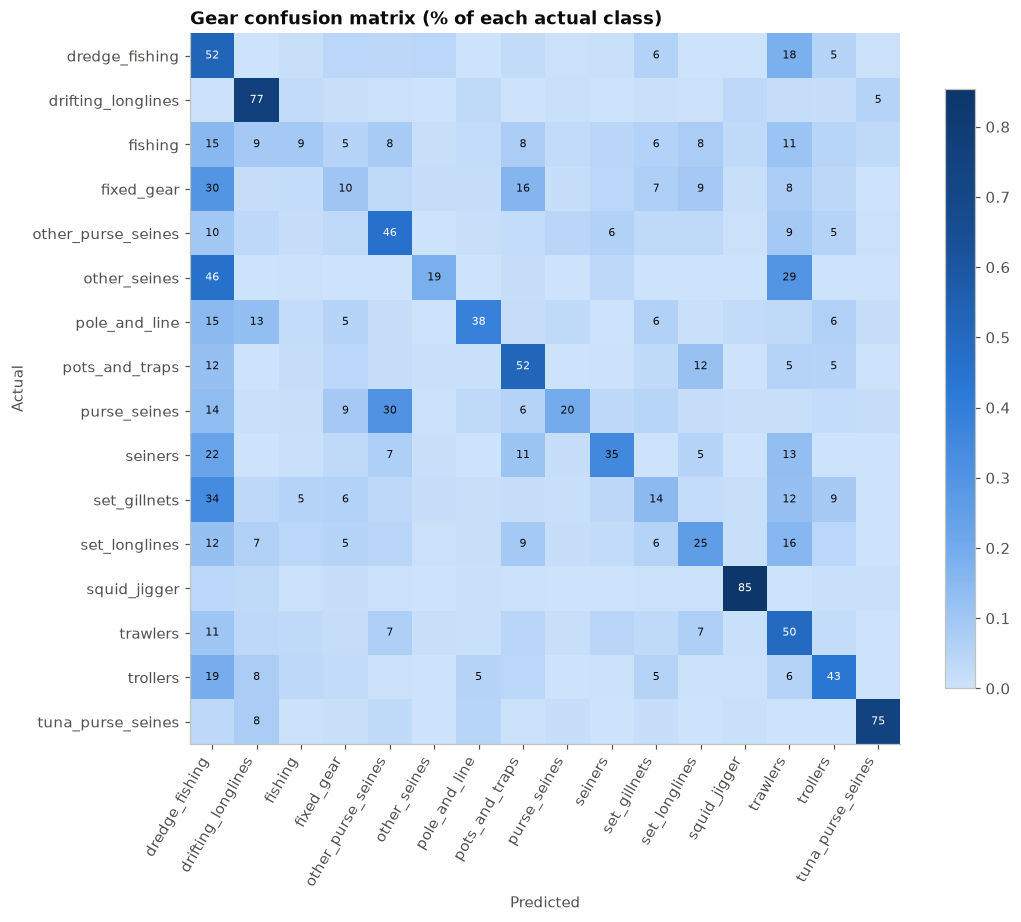

In [14]:
labels = sorted(np.unique(yg))
cmg = confusion_matrix(yg, pg, labels=labels, normalize="true")
fig, ax = plt.subplots(figsize=(10, 8.5))
im = ax.imshow(cmg, cmap=P.SEQ, vmin=0, vmax=max(0.6, cmg.max()))
ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, rotation=60, ha="right"); ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels)
for i in range(len(labels)):
    for j in range(len(labels)):
        if cmg[i, j] >= 0.05:
            ax.text(j, i, f"{cmg[i, j]*100:.0f}", ha="center", va="center", fontsize=7, color="white" if cmg[i, j] > 0.35 else P.INK)
ax.grid(False); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.set_title("Gear confusion matrix (% of each actual class)")
fig.colorbar(im, ax=ax, shrink=0.8); fig.tight_layout(); P.save(fig, FIG / "23_taskC_confusion.png")

In [15]:
off = pd.DataFrame(cmg, index=labels, columns=labels).stack().rename("share").reset_index()
off.columns = ["actual", "predicted", "share"]
off = off[off["actual"] != off["predicted"]].sort_values("share", ascending=False).head(10)
off.round(3)

,actual,predicted,share
80,other_seines,dredge_fishing,0.464
160,set_gillnets,dredge_fishing,0.339
132,purse_seines,other_purse_seines,0.302
48,fixed_gear,dredge_fishing,0.296
93,other_seines,trawlers,0.293
144,seiners,dredge_fishing,0.224
224,trollers,dredge_fishing,0.190
13,dredge_fishing,trawlers,0.183
55,fixed_gear,pots_and_traps,0.162
189,set_longlines,trawlers,0.156


In [16]:
FAMILY = {"purse_seines": "purse seines", "tuna_purse_seines": "purse seines", "other_purse_seines": "purse seines",
          "seiners": "other seines", "other_seines": "other seines",
          "drifting_longlines": "longlines", "set_longlines": "longlines"}
fam = lambda a: np.array([FAMILY.get(x, x) for x in a])
fy, fp = fam(yg), fam(pg)
fam_f1 = f1_score(fy, fp, average="macro"); fam_acc = accuracy_score(fy, fp)
RES["C_family"] = {"macro_f1": float(fam_f1), "accuracy": float(fam_acc), "n_families": int(len(set(fy)))}
print(f"Family level ({len(set(fy))} families): macro-F1 {fam_f1:.3f} | accuracy {fam_acc:.3f}   (16 classes: {mf1:.3f} | {acc:.3f})")

Family level (12 families): macro-F1 0.389 | accuracy 0.404   (16 classes: 0.391 | 0.370)


## 5. What drives the predictions? (permutation importance)
Each input column is shuffled on a test subsample and the drop in score is measured. A large drop means the model relies on that input. Results are for the deployable models.

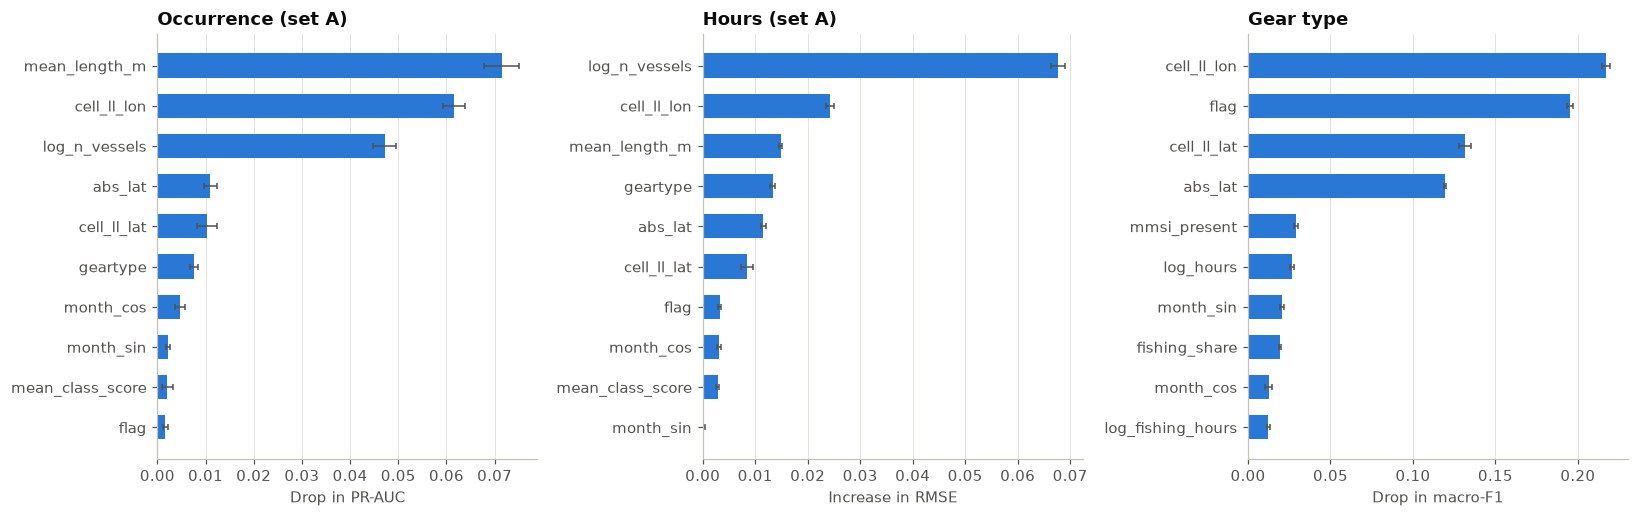

In [17]:
n_pi = 5000 if FAST else 20000
rep_ = 2 if FAST else 5
def perm(pipe, cols, frame, target, scoring):
    s = frame.sample(min(len(frame), n_pi), random_state=SEED)
    r = permutation_importance(pipe, s[cols], s[target], scoring=scoring, n_repeats=rep_, random_state=SEED, n_jobs=1)
    return pd.DataFrame({"mean": r.importances_mean, "sd": r.importances_std}, index=cols).sort_values("mean")

piA = perm(pipeA, colsA, test, "any_fishing", "average_precision")
piH = perm(hA, hcolsA, test_pos, "log_fishing_hours", "neg_root_mean_squared_error")
piG = perm(gm, gcols, test, "geartype", "f1_macro")
RES["importance_top"] = {k: v["mean"].sort_values(ascending=False).head(5).round(4).to_dict() for k, v in [("A", piA), ("B", piH), ("C", piG)]}
fig, ax = plt.subplots(1, 3, figsize=(15, 4.8))
for a, d, t, xl in [(ax[0], piA, "Occurrence (set A)", "Drop in PR-AUC"), (ax[1], piH, "Hours (set A)", "Increase in RMSE"), (ax[2], piG, "Gear type", "Drop in macro-F1")]:
    d = d.tail(10); a.barh(d.index, d["mean"], xerr=d["sd"], color=P.BLUE, height=0.6, error_kw=dict(ecolor=P.MUTED, capsize=2, lw=1))
    a.set_title(t); a.set_xlabel(xl); a.grid(axis="y", visible=False)
fig.tight_layout(); P.save(fig, FIG / "24_permutation_importance.png")

## 6. Would a random split have overstated performance?
The same model, features and rows, scored two ways: a random 80/20 split of rows versus holding out whole geographic blocks. A gap between the two shows how much a random split rewards memorising places.

In [18]:
d = df.sample(min(len(df), 40000 if FAST else 120000), random_state=SEED).reset_index(drop=True)
fs = F.feature_sets(False); cols = fs["num"] + fs["cat"]
def fit_eval(tr, te):
    pipe = Pipeline([("prep", F.make_preprocessor(fs["num"], fs["cat"])), ("m", HistGradientBoostingClassifier(random_state=SEED))])
    pipe.fit(tr[cols], tr["any_fishing"]); p = pipe.predict_proba(te[cols])[:, 1]
    return roc_auc_score(te["any_fishing"], p), average_precision_score(te["any_fishing"], p)
tr_r, te_r = train_test_split(d, test_size=0.2, random_state=SEED)
tr_i, te_i = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED).split(d, groups=d["block"]))
res = pd.DataFrame({"Random row split": fit_eval(tr_r, te_r), "Geographic block split": fit_eval(d.iloc[tr_i], d.iloc[te_i])},
                   index=["ROC-AUC", "PR-AUC"]).T
RES["random_vs_block"] = res.round(4).to_dict("index")
res.round(3)

,ROC-AUC,PR-AUC
Random row split,0.787,0.621
Geographic block split,0.667,0.474


## 7. Bias audit: does performance depend on region or flag group?
AIS coverage is uneven (satellite reception differs by region, and flags are partly inferred from vessel identifiers). If the model works well in some places and poorly in others, conclusions drawn from it are not equally reliable everywhere. ROC-AUC of the deployable occurrence model (set A) by latitude band and by flag group.

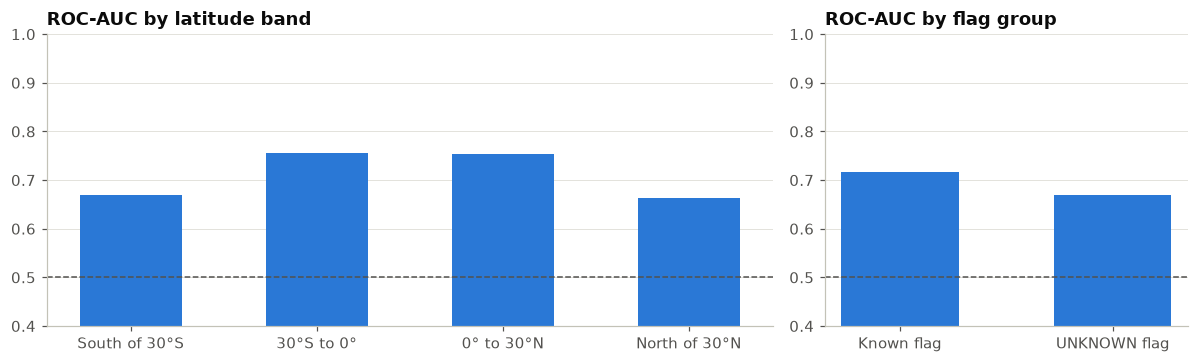

,rows,share_fishing,roc_auc
South of 30°S,3394,0.250,0.669
30°S to 0°,8835,0.335,0.756
0° to 30°N,23088,0.435,0.753
North of 30°N,45950,0.306,0.664
Known flag,75177,0.330,0.717
UNKNOWN flag,6090,0.506,0.670


In [19]:
test = test.assign(p=pA, lat_band=pd.cut(test["cell_ll_lat"], [-90, -30, 0, 30, 90], labels=["South of 30°S", "30°S to 0°", "0° to 30°N", "North of 30°N"]),
                   flag_group=np.where(test["flag"].astype(str).str.startswith("UNKNOWN"), "UNKNOWN flag", "Known flag"))
def audit(col):
    out = []
    for k, idx in test.groupby(col, observed=True).indices.items():
        if len(np.unique(y[idx])) == 2:
            out.append({col: k, "rows": len(idx), "share_fishing": y[idx].mean(), "roc_auc": roc_auc_score(y[idx], pA[idx])})
    return pd.DataFrame(out).set_index(col)
a1, a2 = audit("lat_band"), audit("flag_group")
RES["audit_lat"] = a1["roc_auc"].round(3).to_dict(); RES["audit_flag"] = a2["roc_auc"].round(3).to_dict()
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4), gridspec_kw={"width_ratios": [4, 2]})
for a, d_, t in [(ax[0], a1, "ROC-AUC by latitude band"), (ax[1], a2, "ROC-AUC by flag group")]:
    a.bar([str(i) for i in d_.index], d_["roc_auc"], color=P.BLUE, width=0.55); a.axhline(0.5, color=P.MUTED, lw=1, ls="--")
    a.set_ylim(0.4, 1.0); a.set_title(t); a.grid(axis="x", visible=False)
fig.tight_layout(); P.save(fig, FIG / "25_bias_audit.png")
pd.concat([a1.round(3), a2.round(3)])

## 8. Summary and saved results

In [20]:
with open(ROOT / "reports" / "test_results.json", "w") as f:
    json.dump(clean(RES), f, indent=2)
print("Saved reports/test_results.json")
summary = pd.Series({
    "A  ROC-AUC (set A, deployable)": RES["A"]["Set A (deployable)"]["roc_auc"],
    "A  PR-AUC (set A)": RES["A"]["Set A (deployable)"]["pr_auc"],
    "A  PR-AUC (set B, upper bound)": RES["A"]["Set B (+ hours, mmsi_present)"]["pr_auc"],
    "B  RMSE log hours (set A)": RES["B"]["A"]["rmse"], "B  R2 (set A)": RES["B"]["A"]["r2"], "B  R2 (set B)": RES["B"]["B"]["r2"],
    "C  macro-F1 (16 gear types)": RES["C"]["macro_f1"], "C  macro-F1 (gear families)": RES["C_family"]["macro_f1"],
}).round(3).to_frame("test")
summary

Saved reports/test_results.json


,test
"A ROC-AUC (set A, deployable)",0.720
A PR-AUC (set A),0.562
"A PR-AUC (set B, upper bound)",0.823
B RMSE log hours (set A),1.215
B R2 (set A),0.165
B R2 (set B),0.763
C macro-F1 (16 gear types),0.391
C macro-F1 (gear families),0.389
